# MTA Subway Hourly Ridership – Pemodelan

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fxrdhan/mta-subway-bigdata/blob/main/notebooks/MTA_Subway_Hourly_Ridership_Modeling_2025-01_2026-10.ipynb)

> **Data: *cutoff* 2026-10-08 23:00.** Notebook ini membaca dataset bersih yang sama dengan notebook EDA, tanpa mengunduh ulang data dari API. Seluruh proses berjalan sekitar 5 menit.

### VI. Pemodelan (*Machine Learning*)

Tiga model pada rencana proyek dapat dibangun hanya dengan data *batch*:

1. **Regresi**: memprediksi jumlah penumpang per kompleks stasiun per jam.
2. **Klasifikasi**: memprediksi apakah satu jam di satu stasiun termasuk jam padat.
3. ***Clustering* (K-Means)**: mengelompokkan 428 kompleks stasiun menurut profil jamnya.

Model keempat, deteksi anomali keterlambatan kereta, memerlukan data keterlambatan dari *feed* GTFS-RT dan dikerjakan setelah jalur *streaming* tersedia.

#### 1. Persiapan

In [1]:
import datetime as dt
import sys
import time
from pathlib import Path

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from matplotlib.ticker import FuncFormatter
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, f1_score, mean_absolute_error, precision_score, recall_score, roc_auc_score, silhouette_score

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | duckdb {duckdb.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.16 | pandas 2.2.3 | duckdb 1.3.2 | scikit-learn 1.9.1


Parameter. File bersih dicari di Google Drive lalu di `/content`, sama dengan notebook EDA. Data dibagi menurut waktu: model belajar dari data sampai 30 Juni 2026 dan diuji pada 1 Juli sampai 8 Oktober 2026 (100 hari) yang tidak pernah dilihatnya. Pembagian acak tidak dipakai karena akan membocorkan informasi dari masa depan ke data latih.

In [2]:
CLEAN_NAME = "mta_subway_hourly_ridership_clean_2025-01_2026-10.parquet"
CANDIDATES = [Path("/content/drive/MyDrive") / CLEAN_NAME, Path("/content/mta_subway/04_clean") / CLEAN_NAME]
EXPECTED = {"rows": 46_363_790, "ridership": 2_325_387_032, "transfers": 116_471_753}
IN_COLAB = "google.colab" in sys.modules

FEATURE_START = "2025-01-29"  # first hour with every lag (up to 28 days) available
TEST_START = "2026-07-01"     # train: FEATURE_START .. 2026-06-30, test: 2026-07-01 .. 2026-10-08
TRAIN_SAMPLE = 2_000_000      # training rows sampled from the train period
SEED = 42

Fungsi bantu tampilan dan gaya grafik, sama dengan notebook EDA.

In [3]:
def fmt(x, n=0):
    """Format numbers Indonesian-style: 45243727 -> 45.243.727; 10.63 (n=1) -> 10,6."""
    return f"{x:,.{n}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def show_table(df, n=0):
    """Render a DataFrame without index, with dot thousands separators and no line wrapping."""
    return (
        df.style.format(thousands=".", decimal=",", precision=n)
        .hide(axis="index")
        .set_table_styles([{"selector": "th, td", "props": [("white-space", "nowrap")]}])
    )


BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
THOUSANDS = FuncFormatter(lambda v, _: fmt(v / 1e3))
PERCENT = FuncFormatter(lambda v, _: f"{fmt(v)}%")

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.titlecolor": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "lines.linewidth": 2, "legend.frameon": False,
})

Membuka file bersih sebagai *view* DuckDB `mta` dan memastikan isinya sama dengan nilai acuan.

In [4]:
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")

CLEAN_PATH = next((p for p in CANDIDATES if p.exists()), None)
if CLEAN_PATH is None:
    raise FileNotFoundError(f"{CLEAN_NAME} not found in {[str(p.parent) for p in CANDIDATES]}; run the data wrangling notebook first")

con = duckdb.connect()
con.execute("SET enable_progress_bar=false")
con.execute(f"CREATE OR REPLACE VIEW mta AS SELECT * FROM read_parquet('{CLEAN_PATH}')")

rows, riders, transfers = con.sql("SELECT count(*), sum(ridership), sum(transfers) FROM mta").fetchone()
assert (rows, riders, transfers) == (EXPECTED["rows"], EXPECTED["ridership"], EXPECTED["transfers"]), "Clean file differs from the reference values."
print(f"File : {CLEAN_PATH}")
print(f"Rows : {fmt(rows)} (match the reference)")
STATION_NAMES = con.sql("SELECT station_complex_id AS station, any_value(station_complex) AS station_complex, any_value(borough) AS borough, any_value(latitude) AS latitude, any_value(longitude) AS longitude FROM mta GROUP BY 1").df().set_index("station")

File : /content/mta_subway/04_clean/mta_subway_hourly_ridership_clean_2025-01_2026-10.parquet
Rows : 46.363.790 (match the reference)


#### 2. Data Model: Grid Stasiun-Jam dan Fitur

Satu baris data model adalah satu kompleks stasiun pada satu jam. Baris dataset dijumlahkan dulu menurut metode pembayaran dan kelas tarif, lalu kombinasi stasiun-jam yang tidak tercatat diisi 0, sesuai temuan EDA (1,98% kombinasi tidak tercatat). Jam peralihan DST dikeluarkan karena labelnya ambigu.

In [5]:
t0 = time.time()
con.execute("""
    CREATE OR REPLACE TABLE grid AS
    WITH hours AS (SELECT DISTINCT transit_timestamp AS ts FROM mta WHERE NOT is_dst_transition),
         stations AS (SELECT DISTINCT station_complex_id AS station FROM mta),
         station_hours AS (SELECT transit_timestamp AS ts, station_complex_id AS station, sum(ridership) AS riders
                           FROM mta WHERE NOT is_dst_transition GROUP BY 1, 2)
    SELECT h.ts, s.station, coalesce(sh.riders, 0) AS riders
    FROM hours h CROSS JOIN stations s LEFT JOIN station_hours sh ON sh.ts = h.ts AND sh.station = s.station""")
n_grid, n_hours, n_stations = con.sql("SELECT count(*), count(DISTINCT ts), count(DISTINCT station) FROM grid").fetchone()
print(f"Grid: {fmt(n_stations)} stations x {fmt(n_hours)} hours = {fmt(n_grid)} rows ({fmt(time.time() - t0, 1)} s)")

Grid: 428 stations x 15.501 hours = 6.634.428 rows (2,0 s)


Hari libur nasional Amerika Serikat dihitung dari aturannya (tanggal tetap atau hari ke-n dalam bulan), termasuk hari pengganti bila jatuh pada akhir pekan. EDA menunjukkan hari libur menurunkan penumpang secara tajam.

In [6]:
def nth_weekday(year, month, weekday, n):
    """n-th given weekday (0 = Monday) of a month."""
    day = dt.date(year, month, 1)
    return day + dt.timedelta(days=(weekday - day.weekday()) % 7 + 7 * (n - 1))


def last_weekday(year, month, weekday):
    day = dt.date(year, month + 1, 1) - dt.timedelta(days=1)
    return day - dt.timedelta(days=(day.weekday() - weekday) % 7)


def observed(day):
    """Saturday holidays are observed on Friday, Sunday holidays on Monday."""
    return day + dt.timedelta(days={5: -1, 6: 1}.get(day.weekday(), 0))


def us_federal_holidays(year):
    fixed = [dt.date(year, 1, 1), dt.date(year, 6, 19), dt.date(year, 7, 4), dt.date(year, 11, 11), dt.date(year, 12, 25)]
    by_rule = [nth_weekday(year, 1, 0, 3), nth_weekday(year, 2, 0, 3), last_weekday(year, 5, 0),  # MLK, Presidents, Memorial
               nth_weekday(year, 9, 0, 1), nth_weekday(year, 10, 0, 2), nth_weekday(year, 11, 3, 4)]  # Labor, Columbus, Thanksgiving
    return sorted(set(fixed + [observed(d) for d in fixed] + by_rule))


HOLIDAYS = [d for year in (2025, 2026) for d in us_federal_holidays(year) if d <= dt.date(2026, 10, 8)]
con.execute("CREATE OR REPLACE TABLE holidays AS SELECT * FROM (VALUES " + ", ".join(f"(DATE '{d}')" for d in HOLIDAYS) + ") t(day)")
print(", ".join(f"{d:%Y-%m-%d}" for d in HOLIDAYS))

2025-01-01, 2025-01-20, 2025-02-17, 2025-05-26, 2025-06-19, 2025-07-04, 2025-09-01, 2025-10-13, 2025-11-11, 2025-11-27, 2025-12-25, 2026-01-01, 2026-01-19, 2026-02-16, 2026-05-25, 2026-06-19, 2026-07-03, 2026-07-04, 2026-09-07


Fitur dibangun dalam dua skenario, karena data *ridership* baru dirilis MTA sekitar 6,5 sampai 12 hari setelah jam terjadi:

| Kelompok fitur | Skenario A: data *real-time* tersedia | Skenario B: sesuai rilis MTA |
|---|---|---|
| Kalender | jam, hari, akhir pekan, bulan, hari libur | sama |
| Profil stasiun | rata-rata penumpang stasiun pada hari dan jam yang sama di periode latih (rata-rata biasa dan rata-rata log) | sama |
| Penumpang sebelumnya (jeda) | 1 jam, 2 jam, 24 jam, dan 7 hari sebelumnya | 14, 21, dan 28 hari sebelumnya pada jam yang sama, beserta rata-ratanya |

Skenario A menggambarkan model bila data penumpang tersedia langsung, mis. dari sensor gerbang. Skenario B adalah kondisi nyata saat memakai data portal: data terbaru yang tersedia berumur minimal 14 hari. Profil stasiun hanya dihitung dari periode latih agar data uji tidak bocor. Jeda dicari berdasarkan waktu (mis. `ts - 14 hari`), bukan urutan baris, sehingga jam DST yang hilang tidak menggeser jeda; jeda yang jatuh pada jam tersebut bernilai kosong dan ditangani langsung oleh model.

In [7]:
t0 = time.time()
con.execute(f"""
    CREATE OR REPLACE TABLE profile AS
    SELECT station, isodow(ts) AS dow, hour(ts) AS hour, avg(riders) AS profile_mean, avg(ln(1 + riders)) AS profile_log
    FROM grid WHERE ts < TIMESTAMP '{TEST_START}' GROUP BY 1, 2, 3""")

LAGS = {"lag_1h": "1 HOUR", "lag_2h": "2 HOUR", "lag_24h": "1 DAY", "lag_7d": "7 DAY", "lag_14d": "14 DAY", "lag_21d": "21 DAY", "lag_28d": "28 DAY"}
lag_cols = ", ".join(f"{name}.riders AS {name}" for name in LAGS)
lag_joins = "\n".join(f"LEFT JOIN grid {name} ON {name}.station = g.station AND {name}.ts = g.ts - INTERVAL {step}" for name, step in LAGS.items())
data = con.sql(f"""
    SELECT g.ts, g.station, g.riders,
           hour(g.ts) AS hour, isodow(g.ts) AS dow, CAST(isodow(g.ts) >= 6 AS TINYINT) AS is_weekend, month(g.ts) AS month,
           CAST(CAST(g.ts AS DATE) IN (SELECT day FROM holidays) AS TINYINT) AS is_holiday,
           p.profile_mean, p.profile_log, {lag_cols}
    FROM grid g
    JOIN profile p ON p.station = g.station AND p.dow = isodow(g.ts) AND p.hour = hour(g.ts)
    {lag_joins}
    WHERE g.ts >= TIMESTAMP '{FEATURE_START}'""").df()
data = data.astype({c: "float32" for c in data.columns if data[c].dtype == "float64"}).sort_values(["ts", "station"], ignore_index=True)
data["lag_mean_14_28d"] = data[["lag_14d", "lag_21d", "lag_28d"]].mean(axis=1)

CALENDAR = ["hour", "dow", "is_weekend", "month", "is_holiday", "profile_mean", "profile_log"]
FEATURES_A = CALENDAR + ["lag_1h", "lag_2h", "lag_24h", "lag_7d"]
FEATURES_B = CALENDAR + ["lag_14d", "lag_21d", "lag_28d", "lag_mean_14_28d"]

is_test = data["ts"] >= TEST_START
train, test = data[~is_test], data[is_test]
sample = train.sample(TRAIN_SAMPLE, random_state=SEED)
print(f"Feature table: {fmt(len(data))} rows x {data.shape[1]} columns ({fmt(data.memory_usage().sum() / 1e9, 2)} GB, {fmt(time.time() - t0, 1)} s)")
show_table(pd.DataFrame([
    ("Train", f"{train['ts'].min():%Y-%m-%d} to {train['ts'].max():%Y-%m-%d}", len(train), len(sample)),
    ("Test", f"{test['ts'].min():%Y-%m-%d} to {test['ts'].max():%Y-%m-%d}", len(test), len(test)),
], columns=["split", "period", "rows", "rows_used"]))

Feature table: 6.346.812 rows x 18 columns (0,55 GB, 31,6 s)


split,period,rows,rows_used
Train,2025-01-29 to 2026-06-30,5.319.612,2.000.000
Test,2026-07-01 to 2026-10-08,1.027.200,1.027.200


#### 3. Regresi: Penumpang per Stasiun per Jam

Model yang dipakai adalah *gradient boosting* berbasis histogram (`HistGradientBoostingRegressor`), yang cepat untuk jutaan baris dan menangani nilai kosong secara langsung. Hiperparameter tidak disetel; nilai yang sama dipakai untuk semua model agar perbandingannya adil. Model dilatih pada 2 juta baris acak dari periode latih.

Rencana proyek memakai target $\log(1 + \text{ridership})$ karena distribusinya condong ke kanan. Selain target itu, dicoba juga *loss* Poisson, yang memodelkan logaritma rata-rata penumpang secara langsung sehingga tidak perlu transformasi balik. Dua model sederhana dipakai sebagai pembanding (*baseline*): penumpang pada jam yang sama 7 hari sebelumnya (hanya mungkin pada skenario A), dan profil rata-rata stasiun pada hari dan jam yang sama.

Metrik dihitung pada skala jumlah penumpang: MAE (rata-rata selisih absolut per stasiun-jam), WAPE (total selisih absolut dibagi total penumpang), dan RMSE (lebih sensitif terhadap kesalahan besar).

In [8]:
def regression_metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "WAPE_pct": 100 * np.abs(y_true - y_pred).sum() / y_true.sum(),
            "RMSE": float(np.sqrt(np.mean((y_true - y_pred) ** 2)))}


def fit_regressor(features, loss):
    model = HistGradientBoostingRegressor(loss=loss, max_iter=300, learning_rate=0.1, max_leaf_nodes=63, random_state=SEED)
    target = np.log1p(sample["riders"]) if loss == "squared_error" else sample["riders"]
    model.fit(sample[features], target)
    raw = model.predict(test[features])
    return model, np.clip(np.expm1(raw) if loss == "squared_error" else raw, 0, None)


y_test = test["riders"].to_numpy()
results, predictions, models = [], {}, {}
results.append(("Baseline: same hour 7 days earlier", "A", regression_metrics(y_test, test["lag_7d"].fillna(test["profile_mean"]).to_numpy())))
results.append(("Baseline: station profile", "A and B", regression_metrics(y_test, test["profile_mean"].to_numpy())))
for scenario, features in [("A", FEATURES_A), ("B", FEATURES_B)]:
    for loss, label in [("squared_error", "log(1 + riders) target"), ("poisson", "Poisson loss")]:
        t0 = time.time()
        model, pred = fit_regressor(features, loss)
        results.append((f"Gradient boosting, {label}", scenario, regression_metrics(y_test, pred)))
        predictions[(scenario, loss)], models[(scenario, loss)] = pred, model
        print(f"Scenario {scenario}, {label}: fitted in {fmt(time.time() - t0)} s")

reg_table = pd.DataFrame([{"model": m, "scenario": s, **v} for m, s, v in results])
show_table(reg_table, 2)

Scenario A, log(1 + riders) target: fitted in 23 s


Scenario A, Poisson loss: fitted in 32 s


Scenario B, log(1 + riders) target: fitted in 21 s


Scenario B, Poisson loss: fitted in 26 s


model,scenario,MAE,WAPE_pct,RMSE
Baseline: same hour 7 days earlier,A,"50,82","14,44","188,86"
Baseline: station profile,A and B,"50,68","14,40","155,69"
"Gradient boosting, log(1 + riders) target",A,"35,49","10,08","154,30"
"Gradient boosting, Poisson loss",A,"33,94","9,64","144,83"
"Gradient boosting, log(1 + riders) target",B,"49,84","14,16","204,93"
"Gradient boosting, Poisson loss",B,"46,65","13,25","194,70"


WAPE setiap model, dikelompokkan menurut skenario. Batang abu-abu adalah *baseline*.

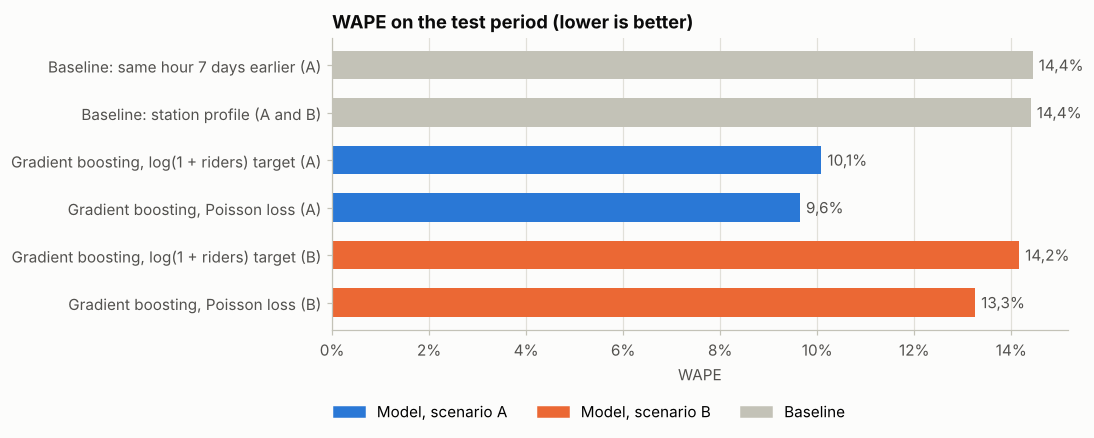

In [9]:
plot = reg_table.iloc[::-1]
colors = [AXIS if m.startswith("Baseline") else BLUE if s == "A" else ORANGE for m, s in zip(plot["model"], plot["scenario"])]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh([f"{m} ({s})" for m, s in zip(plot["model"], plot["scenario"])], plot["WAPE_pct"], color=colors, height=0.6)
for y, value in enumerate(plot["WAPE_pct"]):
    ax.annotate(f"{fmt(value, 1)}%", (value, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK_2)
ax.set(title="WAPE on the test period (lower is better)", xlabel="WAPE")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(PERCENT)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE, AXIS)], labels=["Model, scenario A", "Model, scenario B", "Baseline"],
          loc="upper center", bbox_to_anchor=(0.35, -0.2), ncols=3)
plt.tight_layout()
plt.show()

Prediksi model Poisson kedua skenario dibandingkan dengan penumpang aktual di Grand Central-42 St selama satu minggu pada periode uji, beserta angka pukul 17.00 setiap hari:

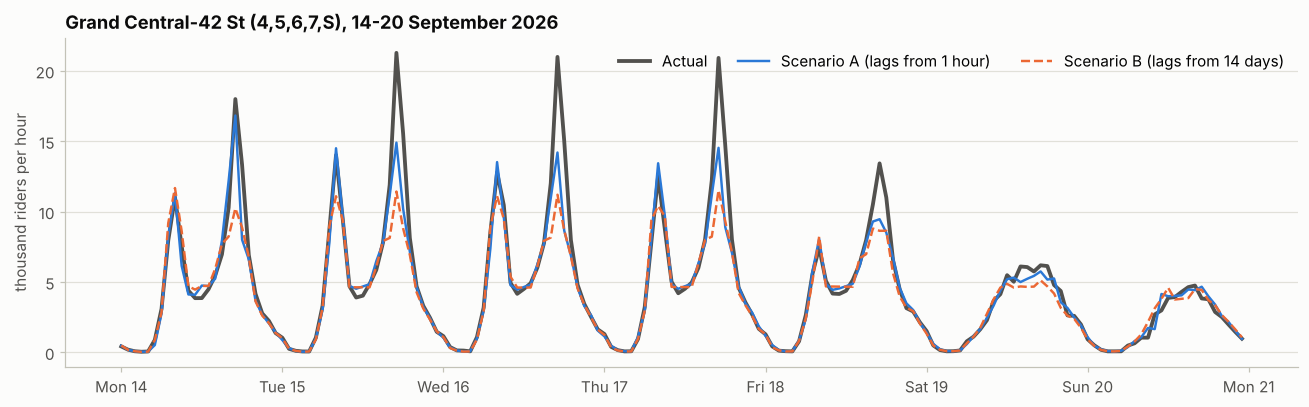

hour,actual,scenario_A,scenario_B
Mon 2026-09-14 17:00,18.001,16.832,10.238
Tue 2026-09-15 17:00,21.283,14.906,11.432
Wed 2026-09-16 17:00,20.996,14.204,11.205
Thu 2026-09-17 17:00,20.925,14.538,11.527
Fri 2026-09-18 17:00,13.433,9.465,8.641
Sat 2026-09-19 17:00,6.192,5.755,5.120
Sun 2026-09-20 17:00,3.836,4.670,4.442


In [10]:
STATION = "610"  # Grand Central-42 St
week = (test["station"] == STATION) & (test["ts"] >= "2026-09-14") & (test["ts"] < "2026-09-21")

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(test.loc[week, "ts"], test.loc[week, "riders"], color=INK_2, linewidth=2.5, label="Actual")
ax.plot(test.loc[week, "ts"], predictions[("A", "poisson")][week.to_numpy()], color=BLUE, linewidth=1.6, label="Scenario A (lags from 1 hour)")
ax.plot(test.loc[week, "ts"], predictions[("B", "poisson")][week.to_numpy()], color=ORANGE, linewidth=1.6, linestyle="--", label="Scenario B (lags from 14 days)")
ax.set(title=f"{STATION_NAMES.loc[STATION, 'station_complex']}, 14-20 September 2026", ylabel="thousand riders per hour")
ax.yaxis.set_major_formatter(THOUSANDS)
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
ax.legend(loc="upper right", ncols=3)
plt.tight_layout()
plt.show()

evening = week.to_numpy() & (test["hour"] == 17).to_numpy()
show_table(pd.DataFrame({"hour": test.loc[evening, "ts"].dt.strftime("%a %Y-%m-%d %H:%M"), "actual": test.loc[evening, "riders"].astype("int64"),
                         "scenario_A": predictions[("A", "poisson")][evening].round().astype("int64"), "scenario_B": predictions[("B", "poisson")][evening].round().astype("int64")}))

Kepentingan fitur dihitung dengan *permutation importance*: kenaikan MAE ketika nilai satu fitur diacak, pada 100.000 baris acak dari periode uji. Semakin besar kenaikannya, semakin besar ketergantungan model pada fitur tersebut.

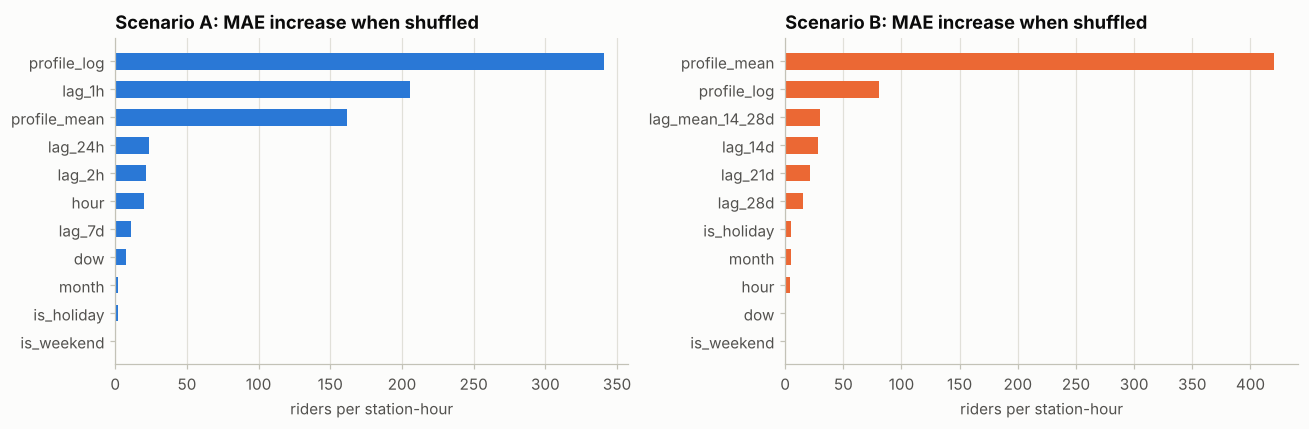

In [11]:
rows = test.sample(100_000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (scenario, features, color) in zip(axes, [("A", FEATURES_A, BLUE), ("B", FEATURES_B, ORANGE)]):
    imp = permutation_importance(models[(scenario, "poisson")], rows[features], rows["riders"], scoring="neg_mean_absolute_error", n_repeats=3, random_state=SEED)
    order = pd.Series(imp.importances_mean, index=features).sort_values()
    ax.barh(order.index, order.values, color=color, height=0.6)
    ax.set(title=f"Scenario {scenario}: MAE increase when shuffled", xlabel="riders per station-hour")
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Temuan:**

- **Skenario A** (data *real-time*): model Poisson menurunkan WAPE dari 14,40% (*baseline* terbaik, profil stasiun) menjadi 9,64%, dan MAE dari 50,68 menjadi 33,94 penumpang per stasiun-jam. Kesalahan berkurang sekitar sepertiga. RMSE turun dari 155,69 menjadi 144,83.
- **Skenario B** (data berumur minimal 14 hari): model Poisson menurunkan WAPE dari 14,40% menjadi 13,25% dan MAE dari 50,68 menjadi 46,65, atau sekitar 8%. RMSE-nya justru lebih buruk daripada profil stasiun (194,70 dibanding 155,69). Artinya, model B lebih tepat pada sebagian besar stasiun-jam tetapi membuat kesalahan besar pada sedikit stasiun-jam dengan penumpang terbanyak.
- Grafik Grand Central menunjukkan sumber kesalahan besar itu: pada Selasa sampai Kamis pukul 17.00 penumpang aktual sekitar 21 ribu, sedangkan prediksi skenario A sekitar 14-15 ribu dan skenario B sekitar 11 ribu (tabel di atas).
- *Loss* Poisson lebih baik daripada target $\log(1 + \text{ridership})$ pada ketiga metrik di kedua skenario. Model Poisson memodelkan logaritma rata-rata penumpang, sehingga tetap sejalan dengan alasan transformasi log pada rencana proyek tanpa perlu transformasi balik.
- Model A paling bergantung pada profil stasiun dan penumpang satu jam sebelumnya, sedangkan model B hampir seluruhnya bergantung pada profil stasiun; data berumur 14-28 hari hanya menambah sedikit informasi.
- Implikasi: selisih WAPE 13,25% (B) dan 9,64% (A) adalah nilai dari data yang lebih segar. Data portal MTA hanya mendukung skenario B. *Feed* GTFS-RT tidak berisi jumlah penumpang, tetapi kondisi layanan terkini darinya (kereta yang lewat, keterlambatan) dapat menjadi fitur tambahan untuk skenario B.

#### 4. Klasifikasi: Jam Padat per Stasiun

Label jam padat ditentukan per stasiun: satu jam disebut padat (`is_peak = 1`) bila penumpangnya mencapai persentil ke-80 jam-jam stasiun itu pada periode latih. Ambang per stasiun dipakai karena EDA menunjukkan skala penumpang antarstasiun sangat timpang, dan jam padat stasiun permukiman (pagi) berbeda dengan stasiun perkantoran (sore). Ambang hanya dihitung dari periode latih.

Model memakai fitur skenario B, yaitu fitur yang benar-benar tersedia saat memakai data portal. Pembandingnya adalah aturan sederhana: jam padat adalah hari kerja pukul 06.00-09.59 dan 16.00-19.59.

In [12]:
threshold = train.groupby("station")["riders"].quantile(0.8).rename("threshold")
labels = data[["station", "riders"]].join(threshold, on="station")
data["is_peak"] = ((labels["riders"] >= labels["threshold"]) & (labels["riders"] > 0)).astype("int8")
train, test = data[~is_test], data[is_test]
sample = train.sample(TRAIN_SAMPLE, random_state=SEED)
print(f"Peak share: train {fmt(100 * train['is_peak'].mean(), 1)}% | test {fmt(100 * test['is_peak'].mean(), 1)}%")

t0 = time.time()
classifier = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=63, random_state=SEED)
classifier.fit(sample[FEATURES_B], sample["is_peak"])
proba = classifier.predict_proba(test[FEATURES_B])[:, 1]
print(f"Classifier fitted in {fmt(time.time() - t0)} s")

y_peak = test["is_peak"].to_numpy()
candidates = {"Gradient boosting (scenario B)": (proba >= 0.5, proba),
              "Rule: weekday 06-09 and 16-19": (((test["dow"] <= 5) & test["hour"].isin([6, 7, 8, 9, 16, 17, 18, 19])).to_numpy(), None)}
show_table(pd.DataFrame([{
    "model": name, "accuracy": (pred == y_peak).mean(), "precision": precision_score(y_peak, pred), "recall": recall_score(y_peak, pred),
    "F1": f1_score(y_peak, pred), "ROC_AUC": roc_auc_score(y_peak, score) if score is not None else np.nan,
} for name, (pred, score) in candidates.items()]), 3)

Peak share: train 20,1% | test 19,0%


Classifier fitted in 11 s


model,accuracy,precision,recall,F1,ROC_AUC
Gradient boosting (scenario B),"0,898","0,751","0,694","0,721","0,941"
Rule: weekday 06-09 and 16-19,"0,835","0,551","0,697","0,615",nan


Matriks konfusi kedua pendekatan pada periode uji (jumlah stasiun-jam):

In [13]:
for name, (pred, _) in candidates.items():
    matrix = confusion_matrix(y_peak, pred)
    print(name)
    display(show_table(pd.DataFrame(matrix, index=["actual: not peak", "actual: peak"], columns=["predicted: not peak", "predicted: peak"]).reset_index(names="")))

Gradient boosting (scenario B)


,predicted: not peak,predicted: peak
actual: not peak,787.337,44.893
actual: peak,59.662,135.308


Rule: weekday 06-09 and 16-19


,predicted: not peak,predicted: peak
actual: not peak,721.566,110.664
actual: peak,59.106,135.864


**Temuan:**

- Model klasifikasi mencapai ROC-AUC 0,941, akurasi 0,898, dan F1 0,721. Aturan jam sibuk sederhana hanya mencapai akurasi 0,835 dan F1 0,615.
- *Recall* keduanya hampir sama (0,694 dan 0,697), tetapi presisi model jauh lebih tinggi (0,751 dibanding 0,551). Alarm palsu turun dari 110.664 menjadi 44.893 stasiun-jam, atau sekitar 59%.
- Aturan sederhana menandai semua stasiun pada jam yang sama, padahal EDA menunjukkan jam padat stasiun permukiman (pagi) dan perkantoran (sore) berbeda. Model mempelajari jam padat tiap stasiun lewat profilnya, sehingga jauh lebih jarang salah menandai.
- Ambang 0,5 dipakai apa adanya. Bila operator lebih mementingkan tidak melewatkan jam padat, ambang dapat diturunkan untuk menaikkan *recall* dengan konsekuensi presisi turun.

#### 5. *Clustering*: Profil Jam Kompleks Stasiun

Setiap kompleks stasiun digambarkan oleh 48 angka: porsi penumpang per jam pada hari kerja (24 angka) dan pada akhir pekan (24 angka). Bentuk porsi dipakai, bukan jumlah penumpang, agar kelompok ditentukan oleh pola waktu dan bukan ukuran stasiun (temuan EDA bagian 7).

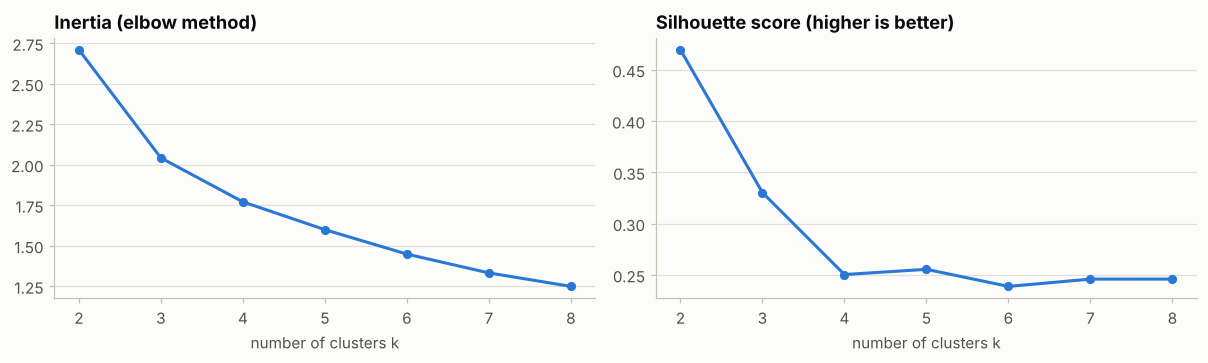

k,inertia,silhouette,smallest_cluster
2,"2,710","0,470",155
3,"2,042","0,330",112
4,"1,771","0,250",82
5,"1,599","0,255",67
6,"1,448","0,239",48
7,"1,332","0,246",22
8,"1,249","0,246",8


In [14]:
hourly_profile = con.sql("""
    SELECT station, CASE WHEN isodow(ts) <= 5 THEN 'weekday' ELSE 'weekend' END AS day_type, hour(ts) AS hour, sum(riders) AS riders
    FROM grid GROUP BY 1, 2, 3""").df().pivot_table(index="station", columns=["day_type", "hour"], values="riders", fill_value=0)
shares = hourly_profile.div(hourly_profile.T.groupby(level=0).transform("sum").T)
X = shares.to_numpy()

k_search = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    k_search.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_), "smallest_cluster": np.bincount(km.labels_).min()})
k_search = pd.DataFrame(k_search)

fig, (ax_in, ax_si) = plt.subplots(1, 2, figsize=(11, 3.4))
ax_in.plot(k_search["k"], k_search["inertia"], color=BLUE, marker="o", markersize=5)
ax_in.set(title="Inertia (elbow method)", xlabel="number of clusters k")
ax_si.plot(k_search["k"], k_search["silhouette"], color=BLUE, marker="o", markersize=5)
ax_si.set(title="Silhouette score (higher is better)", xlabel="number of clusters k")
plt.tight_layout()
plt.show()
show_table(k_search, 3)

Silhouette tertinggi ada pada k = 2 (0,470), tetapi dua kelompok hanya memisahkan pola pagi dan pola sore. Pada k = 3 silhouette masih 0,330, sedangkan mulai k = 4 turun ke sekitar 0,25 dan kelompok terkecil makin kecil (8 stasiun pada k = 8). Kurva *inertia* juga mulai melandai setelah k = 3 (turun 0,67 dari k = 2 ke 3, lalu hanya 0,27 dari k = 3 ke 4). Karena itu dipilih **k = 3**. Nomor *cluster* diurutkan menurut porsi penumpang pagi, dari yang terkecil, agar namanya tetap sama bila notebook dijalankan ulang.

In [15]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X)
weekday, weekend = shares["weekday"], shares["weekend"]
morning = 100 * weekday[[6, 7, 8, 9]].sum(axis=1).to_numpy()
order = pd.Series(morning).groupby(kmeans.labels_).mean().sort_values().index  # number clusters by morning share, so names stay stable
clusters = STATION_NAMES.loc[shares.index].assign(cluster=pd.Series(kmeans.labels_).map({raw: new for new, raw in enumerate(order)}).to_numpy())
daily = con.sql("SELECT station, sum(riders) / count(DISTINCT CAST(ts AS DATE)) AS avg_daily FROM grid GROUP BY 1").df().set_index("station")
n_weekdays, n_weekend_days = con.sql("SELECT count(DISTINCT CAST(ts AS DATE)) FILTER (WHERE isodow(ts) <= 5), count(DISTINCT CAST(ts AS DATE)) FILTER (WHERE isodow(ts) >= 6) FROM grid").fetchone()
clusters = clusters.join(daily)
clusters["am_share"] = 100 * weekday[[6, 7, 8, 9]].sum(axis=1)
clusters["pm_share"] = 100 * weekday[[16, 17, 18, 19]].sum(axis=1)
clusters["weekend_ratio"] = 100 * (hourly_profile["weekend"].sum(axis=1) / n_weekend_days) / (hourly_profile["weekday"].sum(axis=1) / n_weekdays)

summary = clusters.groupby("cluster").agg(stations=("station_complex", "count"), avg_daily=("avg_daily", "mean"), am_share=("am_share", "mean"),
                                          pm_share=("pm_share", "mean"), weekend_ratio=("weekend_ratio", "mean"))
mean_weekday = weekday.groupby(clusters["cluster"].to_numpy()).mean()
summary["weekday_peak_hour"] = mean_weekday.idxmax(axis=1)
summary["weekday_peak_share"] = 100 * mean_weekday.max(axis=1)
summary["manhattan_pct"] = 100 * clusters.assign(m=clusters["borough"].eq("Manhattan")).groupby("cluster")["m"].mean()
summary["busiest_stations"] = clusters.sort_values("avg_daily", ascending=False).groupby("cluster")["station_complex"].apply(lambda s: "; ".join(n.split(" (")[0] for n in s.head(3)))
show_table(summary.reset_index(), 1)

cluster,stations,avg_daily,am_share,pm_share,weekend_ratio,weekday_peak_hour,weekday_peak_share,manhattan_pct,busiest_stations
0,112,"17.214,1","16,2","37,9","66,2",17,"12,5","75,0",Times Sq-42 St/Port Authority Bus Terminal; Grand Central-42 St; 34 St-Herald Sq
1,130,"7.117,6","33,5","24,5","60,6",8,"12,3","23,8",34 St-Penn Station; Flushing-Main St; Jackson Hts-Roosevelt Av/74 St-Broadway
2,186,"4.012,5","42,2","16,7","50,8",7,"14,3","4,3",Jamaica Center-Parsons/Archer; Junction Blvd; Myrtle-Wyckoff Avs


Kolom `weekend_ratio` adalah rata-rata penumpang per hari akhir pekan sebagai persentase rata-rata per hari kerja. Berdasarkan tabel di atas, ketiga *cluster* dinamai:

| *Cluster* | Nama | Ciri |
|:-:|---|---|
| 0 | *Commercial core* | 112 kompleks, 75% di Manhattan, rata-rata 17.214 penumpang per hari; puncak hari kerja pukul 17.00; porsi sore 37,9% dan pagi hanya 16,2% |
| 1 | *Mixed and transfer hubs* | 130 kompleks, rata-rata 7.118 penumpang per hari; puncak pagi dan sore sama-sama ada; termasuk 34 St-Penn Station, Flushing-Main St, dan Jackson Hts-Roosevelt Av |
| 2 | *Residential* | 186 kompleks, hanya 4,3% di Manhattan, rata-rata 4.013 penumpang per hari; puncak hari kerja pukul 07.00; porsi pagi 42,2% |

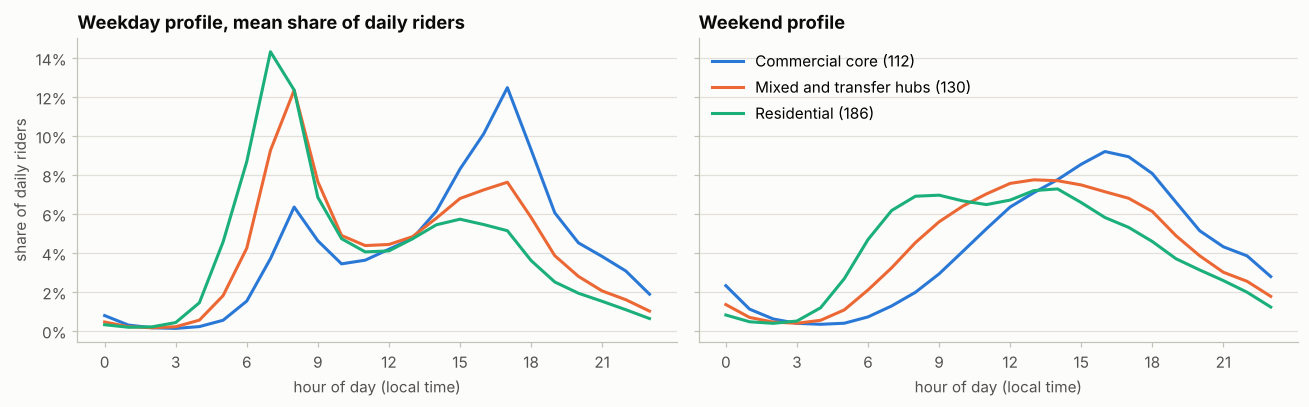

In [16]:
CLUSTER_STYLE = {0: ("Commercial core", BLUE), 1: ("Mixed and transfer hubs", ORANGE), 2: ("Residential", AQUA)}

fig, (ax_wd, ax_we) = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for cluster, (label, color) in CLUSTER_STYLE.items():
    members = clusters.index[clusters["cluster"] == cluster]
    for ax, part in [(ax_wd, weekday), (ax_we, weekend)]:
        values = 100 * part.loc[members].mean()
        ax.plot(values.index, values.values, color=color, label=f"{label} ({len(members)})")
ax_wd.set(title="Weekday profile, mean share of daily riders", xlabel="hour of day (local time)", ylabel="share of daily riders", xticks=range(0, 24, 3))
ax_we.set(title="Weekend profile", xlabel="hour of day (local time)", xticks=range(0, 24, 3))
ax_wd.yaxis.set_major_formatter(PERCENT)
ax_we.legend(loc="upper left")
plt.tight_layout()
plt.show()

Lokasi kompleks stasiun menurut *cluster*; luas lingkaran sebanding dengan rata-rata penumpang harian.

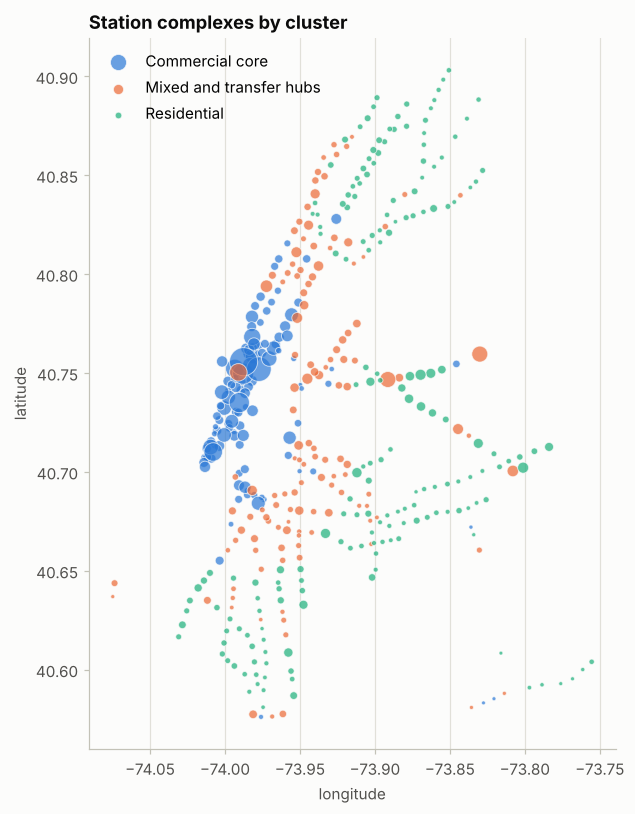

In [17]:
fig, ax = plt.subplots(figsize=(7, 7.5))
for cluster, (label, color) in CLUSTER_STYLE.items():
    part = clusters[clusters["cluster"] == cluster]
    ax.scatter(part["longitude"], part["latitude"], s=part["avg_daily"] / 400 + 6, color=color, alpha=0.7, edgecolors=SURFACE, linewidths=0.6, label=label)
ax.set(title="Station complexes by cluster", xlabel="longitude", ylabel="latitude")
ax.set_aspect(1 / np.cos(np.radians(40.7)))
ax.grid(axis="both")
ax.legend(loc="upper left", markerscale=0.8)
plt.tight_layout()
plt.show()

**Temuan:**

- Pola akhir pekan ikut berbeda. *Commercial core* mempertahankan 66,2% volume hari kerja pada akhir pekan dengan puncak sore, sedangkan *residential* hanya 50,8%, sehingga stasiun pusat kota tetap ramai oleh aktivitas non-kerja.
- Peta menunjukkan *commercial core* terkumpul di Midtown dan Lower Manhattan, *residential* berada di ujung-ujung jalur di Bronx, Brooklyn, dan Queens, dan *mixed* berada di antaranya serta di simpul transfer.
- Implikasi: label *cluster* dapat menjadi fitur untuk regresi dan klasifikasi, dan dapat dipakai operator untuk mengatur jadwal per kelompok stasiun, karena jam puncak tiap kelompok berbeda.

#### 6. Ringkasan dan Keterbatasan

**Ringkasan hasil:**

| Model | Hasil pada periode uji (1 Juli - 8 Oktober 2026) |
|---|---|
| Regresi, skenario A (data *real-time*) | WAPE 9,64% dibanding 14,40% untuk *baseline* terbaik |
| Regresi, skenario B (sesuai rilis MTA) | WAPE 13,25% dibanding 14,40%; RMSE lebih buruk daripada *baseline* karena puncak stasiun terbesar diprediksi terlalu rendah |
| Klasifikasi jam padat | ROC-AUC 0,941, F1 0,721 (aturan sederhana 0,615), alarm palsu turun 59% |
| K-Means | 3 kelompok stasiun: *commercial core* (112), *mixed and transfer hubs* (130), *residential* (186) |

**Keterbatasan:**

- Periode uji (Juli-Oktober 2026) masih dapat direvisi MTA pada rilis mingguan berikutnya, sehingga metrik bisa sedikit bergeser bila dihitung ulang dengan data baru.
- Hiperparameter tidak disetel, dan model dilatih pada 2 juta dari 5,3 juta baris latih. Hasil di atas adalah titik awal, bukan batas kemampuan model.
- Skenario A memerlukan data penumpang *real-time* yang tidak tersedia dari portal MTA, sehingga berfungsi sebagai perbandingan, bukan model yang siap dipakai.
- Model belum memakai faktor luar seperti cuaca atau acara besar; penurunan tajam 25-26 Januari dan 22-23 Februari 2026 yang ditemukan pada EDA belum dapat dijelaskan model.
- Hasil K-Means dapat sedikit berbeda pada versi scikit-learn lain.
- Deteksi anomali keterlambatan belum dikerjakan karena memerlukan data GTFS-RT.

**Langkah berikutnya:** menyetel hiperparameter dengan validasi berbasis waktu, menambahkan label *cluster* dan data cuaca sebagai fitur, lalu menambahkan fitur dari GTFS-RT setelah jalur *streaming* berjalan.